
# Roommate Compatibility Matching — ML + SQLite

This notebook builds an end-to-end **roommate-matching system**:

1. Loads the [`cive202/Lifestyle_Preferences_Dataset`](https://huggingface.co/datasets/cive202/Lifestyle_Preferences_Dataset) (lifestyle/preference data for ~10k people).
2. Engineers features from it and builds **three interchangeable compatibility algorithms** (plus a hand-crafted rule-based baseline):
   - `rule_based` — transparent weighted-feature similarity (also used to generate training labels)
   - `clustering` — unsupervised KMeans lifestyle personas
   - `nearest_neighbor` — direct cosine similarity between people
   - `ml_model` — a supervised RandomForest trained to predict the rule-based compatibility score from pairwise features
   
   Switching between them is a **single config variable** (`ACTIVE_ALGORITHM`).
3. Creates a **SQLite database** with `rooms` (capacity, location, rent...) and `people` (referencing their room via a foreign key), seeded with sample data.
4. Takes a **new/test person's profile**, computes their average compatibility with the current occupants of every room that still has space, and returns a **ranked list of suitable rooms** (plus any brand-new/empty rooms that have no roommates yet to score against).

> **Important note on the data:** the dataset gives each person's *individual* lifestyle preferences — it does **not** contain a ready-made "these two people are compatible" label. So there is no ground truth to directly supervise a model on. To still deliver a genuine ML model, this notebook (a) defines a transparent rule-based compatibility formula from domain knowledge, then (b) trains a RandomForest to *learn and generalize* that scoring function from pairwise features — that trained model is `ml_model` below. The clustering and nearest-neighbor methods are unsupervised alternatives that don't need this label at all.

> **Note on running this notebook:** it tries to download the real dataset from Hugging Face first. If there's no internet access (or the file has moved), it automatically falls back to a locally generated synthetic dataset with the *exact same columns*, so every cell below still runs end-to-end.


## 1. Imports & setup

In [1]:

import warnings
warnings.filterwarnings("ignore")

import sqlite3
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler, MultiLabelBinarizer
from sklearn.cluster import KMeans
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.decomposition import PCA

import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)


## 2. Load the dataset (Hugging Face, with an offline-safe fallback)

In [2]:

DATA_URL = "https://huggingface.co/datasets/cive202/Lifestyle_Preferences_Dataset/resolve/main/roommate_dataset.csv"

def generate_synthetic_fallback(n=1200, seed=RANDOM_SEED):
    '''Synthetic data that mirrors the Lifestyle_Preferences_Dataset schema exactly.
    Only used if the live Hugging Face download is unavailable, so the notebook
    still runs end-to-end offline.'''
    rng = np.random.default_rng(seed)
    genders = ["male", "female", "non_binary", "prefer_not_to_say"]
    occupations = ["Student", "Intern", "Fresh Graduate", "Young Professional"]
    locations = ["Kathmandu", "Lalitpur", "Bhaktapur", "Pokhara", "Chitwan", "Butwal",
                 "Biratnagar", "Dharan", "Itahari", "Nepalgunj", "Birgunj", "Hetauda"]
    sleep_schedules = ["early_bird", "night_owl", "flexible"]
    smoking_opts = ["non_smoker", "smoker", "occasional"]
    drinking_opts = ["non_drinker", "drinker", "social"]
    guests_opts = ["rarely", "sometimes", "frequently"]
    food_opts = ["vegetarian", "non_vegetarian", "vegan", "no_preference"]
    pet_opts = ["okay_with_pets", "not_okay_with_pets", "no_pets", "has_pets"]
    study_opts = ["quiet", "group_study", "background_noise_ok", "rarely_studies_at_home"]
    interest_pool = ["Hiking", "Photography", "Treks", "Music", "Gaming", "Cooking", "Language",
                      "Book Club", "Travel", "Yoga", "Futsal", "Board Games"]
    gender_pref_opts = ["male", "female", "non_binary", "any"]
    room_type_opts = ["any", "shared_room", "private_room", "entire_place"]

    rows = []
    for i in range(n):
        budget_min = int(rng.integers(4000, 35000))
        budget_max = budget_min + int(rng.integers(1000, 15000))
        n_interests = int(rng.integers(1, 4))
        interests = "|".join(rng.choice(interest_pool, size=n_interests, replace=False))
        rows.append({
            "user_id": 100000 + i,
            "age": int(rng.integers(18, 33)),
            "gender": rng.choice(genders, p=[0.45, 0.45, 0.05, 0.05]),
            "occupation": rng.choice(occupations),
            "location": rng.choice(locations),
            "budget_min": budget_min,
            "budget_max": budget_max,
            "sleep_schedule": rng.choice(sleep_schedules),
            "wake_time": f"{int(rng.integers(4, 13)):02d}:{int(rng.integers(0, 60)):02d}",
            "smoking": rng.choice(smoking_opts, p=[0.75, 0.10, 0.15]),
            "drinking": rng.choice(drinking_opts, p=[0.40, 0.25, 0.35]),
            "cleanliness": int(rng.integers(1, 6)),
            "noise_level": int(rng.integers(1, 6)),
            "guests_preference": rng.choice(guests_opts),
            "food_preference": rng.choice(food_opts),
            "pets": rng.choice(pet_opts),
            "study_habit": rng.choice(study_opts),
            "interests": interests,
            "gender_preference": rng.choice(gender_pref_opts),
            "room_type_preference": rng.choice(room_type_opts),
        })
    return pd.DataFrame(rows)

try:
    df = pd.read_csv(DATA_URL)
    print(f"Loaded LIVE dataset from Hugging Face: {df.shape[0]} rows, {df.shape[1]} columns")
except Exception as e:
    print(f"Could not reach Hugging Face ({type(e).__name__}: {e}).")
    print("Falling back to a locally generated synthetic dataset with the same schema.")
    df = generate_synthetic_fallback(n=1200)
    print(f"Synthetic dataset generated: {df.shape[0]} rows, {df.shape[1]} columns")

df.head()


Loaded LIVE dataset from Hugging Face: 10000 rows, 20 columns


,user_id,age,gender,occupation,location,budget_min,budget_max,sleep_schedule,wake_time,smoking,drinking,cleanliness,noise_level,guests_preference,food_preference,pets,study_habit,interests,gender_preference,room_type_preference
0,100000,21,female,Student,Bhaktapur,13000,17100,night_owl,08:33,non_smoker,non_drinker,4,1,sometimes,no_preference,not_okay_with_pets,group_study,Hiking|Photography,male,any
1,100001,20,male,Student,Kathmandu,11500,15700,night_owl,08:46,non_smoker,non_drinker,4,3,sometimes,vegetarian,okay_with_pets,quiet,Hiking|Photography|Treks,non_binary,entire_place
2,100002,23,female,Intern,Kathmandu,14600,18000,early_bird,05:12,non_smoker,social,4,3,frequently,non_vegetarian,okay_with_pets,background_noise_ok,Book Club|Hiking|Music,any,any
3,100003,19,female,Student,Kathmandu,6500,9200,night_owl,10:56,non_smoker,social,3,4,frequently,non_vegetarian,no_pets,background_noise_ok,Board Games|Gaming|Music,any,shared_room
4,100004,19,female,Student,Kathmandu,5900,6900,night_owl,07:59,non_smoker,non_drinker,4,2,rarely,non_vegetarian,okay_with_pets,rarely_studies_at_home,Gaming|Music,male,any


## 3. Quick exploration

In [3]:

print(df.shape)
print(df.dtypes)
print("\nMissing values per column:\n", df.isna().sum())


(10000, 20)
user_id                  int64
age                      int64
gender                  object
occupation              object
location                object
budget_min               int64
budget_max               int64
sleep_schedule          object
wake_time               object
smoking                 object
drinking                object
cleanliness              int64
noise_level              int64
guests_preference       object
food_preference         object
pets                    object
study_habit             object
interests               object
gender_preference       object
room_type_preference    object
dtype: object

Missing values per column:
 user_id                 0
age                     0
gender                  0
occupation              0
location                0
budget_min              0
budget_max              0
sleep_schedule          0
wake_time               0
smoking                 0
drinking                0
cleanliness             0
noise_level  

In [4]:

df.describe(include="all").T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
user_id,10000.0,NaN,NaN,NaN,104999.5,2886.89568,100000.0,102499.75,104999.5,107499.25,109999.0
age,10000.0,NaN,NaN,NaN,23.1934,3.753746,18.0,20.0,23.0,25.0,32.0
gender,10000,4,male,4679,NaN,NaN,NaN,NaN,NaN,NaN,NaN
occupation,10000,4,Student,5371,NaN,NaN,NaN,NaN,NaN,NaN,NaN
location,10000,25,Kathmandu,1667,NaN,NaN,NaN,NaN,NaN,NaN,NaN
budget_min,10000.0,NaN,NaN,NaN,12273.51,6133.647809,2200.0,8100.0,10800.0,14600.0,47000.0
budget_max,10000.0,NaN,NaN,NaN,15484.87,7595.652011,3200.0,10200.0,13700.0,18300.0,50000.0
sleep_schedule,10000,3,early_bird,3683,NaN,NaN,NaN,NaN,NaN,NaN,NaN
wake_time,10000,490,05:41,58,NaN,NaN,NaN,NaN,NaN,NaN,NaN
smoking,10000,3,non_smoker,7746,NaN,NaN,NaN,NaN,NaN,NaN,NaN



## 4. Feature engineering

We turn each person's raw record into a numeric feature vector so we can measure similarity between any two people:

- **Numeric fields** (`age`, `budget_min`, `budget_max`, `cleanliness`, `noise_level`) → standardized (z-score).
- **Nominal categorical fields** (gender, occupation, location, sleep schedule, smoking, drinking, guest/food/pet preference, study habit, gender preference, room-type preference) → one-hot encoded.
- **`interests`** (pipe-separated, e.g. `"Hiking|Music"`) → multi-hot encoded so shared interests can be measured with a Jaccard/overlap-style signal.

This produces a single `feature_df` (one row per `user_id`) that every compatibility algorithm below reuses.


In [5]:

NUMERIC = ["age", "budget_min", "budget_max", "cleanliness", "noise_level"]
CATEGORICAL_NOMINAL = ["gender", "occupation", "location", "sleep_schedule", "smoking", "drinking",
                        "guests_preference", "food_preference", "pets", "study_habit",
                        "gender_preference", "room_type_preference"]

def build_feature_matrix(data: pd.DataFrame):
    data = data.copy().reset_index(drop=True)

    scaler = StandardScaler()
    numeric_scaled = pd.DataFrame(scaler.fit_transform(data[NUMERIC]), columns=NUMERIC)

    onehot = pd.get_dummies(data[CATEGORICAL_NOMINAL], prefix=CATEGORICAL_NOMINAL)

    interest_lists = data["interests"].fillna("").apply(lambda s: [i for i in s.split("|") if i])
    mlb = MultiLabelBinarizer()
    interests_encoded = pd.DataFrame(
        mlb.fit_transform(interest_lists),
        columns=[f"interest_{c}" for c in mlb.classes_]
    )

    features = pd.concat([numeric_scaled, onehot, interests_encoded], axis=1)
    features.index = data["user_id"]
    return features, scaler, mlb

feature_df, scaler, mlb = build_feature_matrix(df)
df_indexed = df.set_index("user_id")
print("Feature matrix shape:", feature_df.shape)
feature_df.head()


Feature matrix shape: (10000, 82)


,age,budget_min,budget_max,cleanliness,noise_level,gender_female,gender_male,gender_non_binary,gender_prefer_not_to_say,occupation_Fresh Graduate,occupation_Intern,occupation_Student,occupation_Young Professional,location_Balkumari,location_Baneshwor,location_Bhaktapur,location_Biratnagar,location_Birgunj,location_Boudha,location_Budhanilkantha,location_Butwal,location_Chabahil,location_Chitwan,location_Dharan,location_Gongabu,...,pets_okay_with_pets,study_habit_background_noise_ok,study_habit_group_study,study_habit_quiet,study_habit_rarely_studies_at_home,gender_preference_any,gender_preference_female,gender_preference_male,gender_preference_non_binary,room_type_preference_any,room_type_preference_entire_place,room_type_preference_private_room,room_type_preference_shared_room,interest_Board Games,interest_Book Club,interest_Cooking,interest_Futsal,interest_Gaming,interest_Hiking,interest_Language,interest_Music,interest_Photography,interest_Travel,interest_Treks,interest_Yoga
user_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
100000,-0.584352,0.118449,0.212649,0.623266,-1.637204,True,False,False,False,False,False,True,False,False,False,True,False,False,False,False,False,False,False,False,False,...,False,False,True,False,False,False,False,True,False,True,False,False,False,0,0,0,0,0,1,0,0,1,0,0,0
100001,-0.850766,-0.126116,0.028324,0.623266,0.097030,False,True,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,...,True,False,False,True,False,False,False,False,True,False,True,False,False,0,0,0,0,0,1,0,0,1,0,1,0
100002,-0.051524,0.379319,0.331144,0.623266,0.097030,True,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,...,True,True,False,False,False,True,False,False,False,True,False,False,False,0,1,0,0,0,1,0,1,0,0,0,0
100003,-1.117180,-0.941332,-0.827471,-0.362758,0.964147,True,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,...,False,True,False,False,False,True,False,False,False,False,False,False,True,1,0,0,0,1,0,0,1,0,0,0,0
100004,-1.117180,-1.039158,-1.130291,0.623266,-0.770087,True,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,...,True,False,False,False,True,False,False,True,False,True,False,False,False,0,0,0,0,1,0,0,1,0,0,0,0



## 5. Rule-based compatibility score (our training signal)

Since the dataset has no ready-made pairwise label, we define a transparent, weighted scoring function grounded in common roommate-matching logic (sleep-schedule alignment, cleanliness/noise similarity, smoking/drinking compatibility, budget overlap, shared interests, mutual gender-preference fit, etc.). It returns a score from **0–100**.

This function is used two ways:
1. As a **standalone algorithm** (`rule_based`) — fully explainable, no training needed.
2. As the **label generator** for training the supervised ML model in the next section.


In [6]:

def rule_based_compatibility(row_a, row_b) -> float:
    '''Weighted, hand-crafted roommate compatibility score in [0, 100]. Higher = more compatible.'''
    score = 0.0
    weight_total = 0.0

    def add(weight, match):
        nonlocal score, weight_total
        score += weight * match
        weight_total += weight

    add(15, 1.0 if row_a["sleep_schedule"] == row_b["sleep_schedule"]
             else (0.5 if "flexible" in (row_a["sleep_schedule"], row_b["sleep_schedule"]) else 0.0))

    add(15, 1 - abs(row_a["cleanliness"] - row_b["cleanliness"]) / 4)
    add(10, 1 - abs(row_a["noise_level"] - row_b["noise_level"]) / 4)

    add(12, 1.0 if row_a["smoking"] == row_b["smoking"]
             else (0.4 if "occasional" in (row_a["smoking"], row_b["smoking"]) else 0.0))

    add(8, 1.0 if row_a["drinking"] == row_b["drinking"] else 0.3)
    add(8, 1.0 if row_a["guests_preference"] == row_b["guests_preference"] else 0.3)
    add(7, 1.0 if row_a["pets"] == row_b["pets"] else 0.3)
    add(7, 1.0 if row_a["study_habit"] == row_b["study_habit"] else 0.3)

    lo = max(row_a["budget_min"], row_b["budget_min"])
    hi = min(row_a["budget_max"], row_b["budget_max"])
    overlap = max(0, hi - lo)
    span = max(row_a["budget_max"] - row_a["budget_min"], row_b["budget_max"] - row_b["budget_min"], 1)
    add(10, min(1.0, overlap / span))

    ia = set(str(row_a["interests"]).split("|")) if pd.notna(row_a["interests"]) else set()
    ib = set(str(row_b["interests"]).split("|")) if pd.notna(row_b["interests"]) else set()
    jaccard = len(ia & ib) / len(ia | ib) if (ia | ib) else 0.0
    add(8, jaccard)

    def gender_ok(pref, other_gender):
        return pref == "any" or pref == other_gender
    gender_match = 1.0 if (gender_ok(row_a["gender_preference"], row_b["gender"]) and
                            gender_ok(row_b["gender_preference"], row_a["gender"])) else 0.0
    add(10, gender_match)

    return round(100 * score / weight_total, 2)

# sanity check on the first two people in the dataset
_a, _b = df_indexed.index[0], df_indexed.index[1]
print(f"Example rule-based score between user {_a} and user {_b}: "
      f"{rule_based_compatibility(df_indexed.loc[_a], df_indexed.loc[_b])}")


Example rule-based score between user 100000 and user 100001: 71.78



## 6. Three more compatibility algorithms — clustering, nearest-neighbor, and a trained ML model

All four methods (`rule_based` from above, plus the three below) take two `user_id`s and return a 0–100 compatibility score, so they're fully interchangeable.


In [7]:

# ---- (a) Unsupervised clustering ------------------------------------------------
N_CLUSTERS = 8
kmeans = KMeans(n_clusters=N_CLUSTERS, random_state=RANDOM_SEED, n_init=10)
df_indexed["lifestyle_cluster"] = kmeans.fit_predict(feature_df.values)

_feat_range = feature_df.values.max(axis=0) - feature_df.values.min(axis=0)
_MAX_FEATURE_DIST = np.linalg.norm(_feat_range)
_centroid_range = kmeans.cluster_centers_.max(axis=0) - kmeans.cluster_centers_.min(axis=0)
_MAX_CENTROID_DIST = np.linalg.norm(_centroid_range) or 1.0

def clustering_compatibility(user_id_a, user_id_b, feature_df=feature_df, kmeans=kmeans) -> float:
    '''Compatibility from unsupervised clustering: people in the same lifestyle persona (cluster)
    score highly; people in different clusters score lower, decaying with centroid distance.'''
    vec_a = feature_df.loc[user_id_a].values.astype(float)
    vec_b = feature_df.loc[user_id_b].values.astype(float)
    cluster_a = int(kmeans.predict(vec_a.reshape(1, -1))[0])
    cluster_b = int(kmeans.predict(vec_b.reshape(1, -1))[0])

    if cluster_a == cluster_b:
        dist = np.linalg.norm(vec_a - vec_b)
        return round(100 * (1 - min(dist / (_MAX_FEATURE_DIST or 1.0), 1.0)), 2)
    else:
        centroid_dist = np.linalg.norm(kmeans.cluster_centers_[cluster_a] - kmeans.cluster_centers_[cluster_b])
        return round(70 * (1 - min(centroid_dist / _MAX_CENTROID_DIST, 1.0)), 2)


# ---- (b) Nearest-neighbor / direct similarity -----------------------------------
def nearest_neighbor_compatibility(user_id_a, user_id_b, feature_df=feature_df) -> float:
    '''Direct cosine similarity between two people's feature vectors.'''
    vec_a = feature_df.loc[user_id_a].values.reshape(1, -1)
    vec_b = feature_df.loc[user_id_b].values.reshape(1, -1)
    sim = cosine_similarity(vec_a, vec_b)[0][0]
    return round(100 * max(0.0, sim), 2)

def find_nearest_neighbors(user_id, feature_df=feature_df, k=5):
    '''Utility: k most similar people to `user_id` by cosine similarity (not used for room
    matching directly, but handy for exploring the dataset).'''
    nn = NearestNeighbors(n_neighbors=k + 1, metric="cosine").fit(feature_df.values)
    dist, idx = nn.kneighbors(feature_df.loc[[user_id]].values)
    neighbor_ids = feature_df.index[idx[0]]
    sims = 1 - dist[0]
    pairs = [(uid, round(100 * s, 2)) for uid, s in zip(neighbor_ids, sims) if uid != user_id]
    return pairs[:k]


# ---- (c) Supervised ML model -----------------------------------------------------
def make_pair_features(vec_a, vec_b):
    '''Symmetric pairwise representation (order-independent): abs diff + elementwise product.'''
    vec_a = np.asarray(vec_a, dtype=float)
    vec_b = np.asarray(vec_b, dtype=float)
    return np.concatenate([np.abs(vec_a - vec_b), vec_a * vec_b])

rng = np.random.default_rng(RANDOM_SEED)
all_ids = feature_df.index.to_numpy()
n_pairs = min(8000, len(all_ids) * 15)
idx_a = rng.integers(0, len(all_ids), n_pairs)
idx_b = rng.integers(0, len(all_ids), n_pairs)
keep = idx_a != idx_b
ids_a, ids_b = all_ids[idx_a[keep]], all_ids[idx_b[keep]]

X_pairs = np.array([make_pair_features(feature_df.loc[a], feature_df.loc[b]) for a, b in zip(ids_a, ids_b)])
y_pairs = np.array([rule_based_compatibility(df_indexed.loc[a], df_indexed.loc[b]) for a, b in zip(ids_a, ids_b)])

X_train, X_test, y_train, y_test = train_test_split(X_pairs, y_pairs, test_size=0.2, random_state=RANDOM_SEED)

ml_model = RandomForestRegressor(n_estimators=200, max_depth=12, random_state=RANDOM_SEED, n_jobs=-1)
ml_model.fit(X_train, y_train)

pred = ml_model.predict(X_test)
print(f"Trained on {len(X_train)} pairs, validated on {len(X_test)} pairs.")
print(f"Validation MAE : {mean_absolute_error(y_test, pred):.2f} (points out of 100)")
print(f"Validation R^2 : {r2_score(y_test, pred):.3f}")

def ml_compatibility(user_id_a, user_id_b, feature_df=feature_df, model=ml_model) -> float:
    '''Learned compatibility score: a RandomForest trained to predict rule_based_compatibility
    from pairwise features. Generalizes to any new person's feature vector without retraining.'''
    pair_feat = make_pair_features(feature_df.loc[user_id_a], feature_df.loc[user_id_b]).reshape(1, -1)
    return round(float(model.predict(pair_feat)[0]), 2)


Trained on 6400 pairs, validated on 1600 pairs.
Validation MAE : 4.69 (points out of 100)
Validation R^2 : 0.692



## 7. Pluggable dispatcher — switch algorithms with one variable

`get_compatibility(id_a, id_b, method=...)` routes to whichever algorithm you want. Change `ACTIVE_ALGORITHM` below (or pass `method=` explicitly anywhere) to switch the whole notebook's behavior — no other code needs to change.


In [8]:

ALL_METHODS = ["rule_based", "clustering", "nearest_neighbor", "ml_model"]

# <<< CHANGE THIS ONE LINE TO SWITCH THE ACTIVE ALGORITHM >>>
ACTIVE_ALGORITHM = "ml_model"   # one of: "rule_based", "clustering", "nearest_neighbor", "ml_model"

def get_compatibility(id_a, id_b, method=None, feature_df=feature_df, person_df=df_indexed):
    method = method or ACTIVE_ALGORITHM
    if method == "rule_based":
        return rule_based_compatibility(person_df.loc[id_a], person_df.loc[id_b])
    elif method == "clustering":
        return clustering_compatibility(id_a, id_b, feature_df=feature_df)
    elif method == "nearest_neighbor":
        return nearest_neighbor_compatibility(id_a, id_b, feature_df=feature_df)
    elif method == "ml_model":
        return ml_compatibility(id_a, id_b, feature_df=feature_df)
    else:
        raise ValueError(f"Unknown method: {method}. Choose from {ALL_METHODS}")

# Compare all four methods on the same example pair
_a, _b = df_indexed.index[0], df_indexed.index[1]
comparison = pd.DataFrame({
    "method": ALL_METHODS,
    "compatibility_score": [get_compatibility(_a, _b, method=m) for m in ALL_METHODS],
})
comparison


,method,compatibility_score
0,rule_based,71.78
1,clustering,51.66
2,nearest_neighbor,45.96
3,ml_model,66.00



## 8. SQLite database — rooms & people

Two tables:
- **`rooms`**: `room_id` (PK), name, location, room type, `capacity`, monthly rent.
- **`people`**: `person_id` (PK, = dataset `user_id`), their lifestyle fields, and `room_id` (FK → `rooms.room_id`) showing which room they currently live in.

We seed 8 sample rooms with different capacities, and assign a sample of real people from the dataset into some of them — deliberately leaving a few rooms with open slots (and one completely empty "new" room) so the matching step in Section 9 has real candidates to rank.


In [9]:

DB_PATH = "roommate_system.db"
conn = sqlite3.connect(DB_PATH)
cur = conn.cursor()

cur.executescript('''
DROP TABLE IF EXISTS people;
DROP TABLE IF EXISTS rooms;

CREATE TABLE rooms (
    room_id       INTEGER PRIMARY KEY,
    room_name     TEXT NOT NULL,
    location      TEXT,
    room_type     TEXT,
    capacity      INTEGER NOT NULL,
    monthly_rent  INTEGER
);

CREATE TABLE people (
    person_id             INTEGER PRIMARY KEY,
    age                   INTEGER,
    gender                TEXT,
    occupation            TEXT,
    location              TEXT,
    budget_min            INTEGER,
    budget_max            INTEGER,
    sleep_schedule        TEXT,
    smoking               TEXT,
    drinking              TEXT,
    cleanliness           INTEGER,
    noise_level           INTEGER,
    guests_preference     TEXT,
    food_preference       TEXT,
    pets                  TEXT,
    study_habit           TEXT,
    interests             TEXT,
    gender_preference     TEXT,
    room_type_preference  TEXT,
    lifestyle_cluster     INTEGER,
    room_id               INTEGER REFERENCES rooms(room_id)
);
''')
conn.commit()

sample_rooms = [
    (1, "Sunrise Hostel - Room A",     "Kathmandu", "shared_room",  3,  9000),
    (2, "Sunrise Hostel - Room B",     "Kathmandu", "shared_room",  2, 11000),
    (3, "Green Valley PG - Room 1",    "Lalitpur",  "private_room", 1, 15000),
    (4, "Green Valley PG - Room 2",    "Lalitpur",  "shared_room",  4,  8000),
    (5, "Hilltop Apartments - Unit 3", "Pokhara",   "entire_place", 2, 20000),
    (6, "Riverside Rooms - R5",        "Bhaktapur", "shared_room",  3,  9500),
    (7, "City Center Flat - F2",       "Kathmandu", "entire_place", 3, 24000),
    (8, "Budget Rooms - B1",           "Chitwan",   "shared_room",  4,  6500),
]
cur.executemany("INSERT INTO rooms VALUES (?,?,?,?,?,?)", sample_rooms)
conn.commit()
print(f"Inserted {len(sample_rooms)} sample rooms.")


Inserted 8 sample rooms.


In [10]:

# Seed each room with a handful of real people from the dataset, leaving some slots open
# on purpose (room 3 and room 8 are left with zero occupants -> "brand new" rooms).
occupancy_plan = {1: 2, 2: 2, 3: 0, 4: 3, 5: 1, 6: 3, 7: 2, 8: 0}

sample_people = df.sample(n=sum(occupancy_plan.values()), random_state=7).reset_index(drop=True)

people_rows = []
pos = 0
for room_id, n_occ in occupancy_plan.items():
    for _ in range(n_occ):
        p = sample_people.iloc[pos]
        cluster = int(df_indexed.loc[p["user_id"], "lifestyle_cluster"])
        people_rows.append((
            int(p["user_id"]), int(p["age"]), p["gender"], p["occupation"], p["location"],
            int(p["budget_min"]), int(p["budget_max"]), p["sleep_schedule"], p["smoking"],
            p["drinking"], int(p["cleanliness"]), int(p["noise_level"]), p["guests_preference"],
            p["food_preference"], p["pets"], p["study_habit"], p["interests"],
            p["gender_preference"], p["room_type_preference"], cluster, int(room_id),
        ))
        pos += 1

cur.executemany("INSERT INTO people VALUES (?,?,?,?,?,?,?,?,?,?,?,?,?,?,?,?,?,?,?,?,?)", people_rows)
conn.commit()
print(f"Inserted {len(people_rows)} people across {sum(1 for v in occupancy_plan.values() if v > 0)} occupied rooms.")


Inserted 13 people across 6 occupied rooms.


In [11]:

# Occupancy overview straight from SQLite (JOIN + GROUP BY)
occupancy_query = '''
SELECT r.room_id, r.room_name, r.location, r.room_type, r.monthly_rent, r.capacity,
       COUNT(p.person_id) AS current_occupants,
       (r.capacity - COUNT(p.person_id)) AS available_slots
FROM rooms r
LEFT JOIN people p ON p.room_id = r.room_id
GROUP BY r.room_id
ORDER BY r.room_id;
'''
pd.read_sql_query(occupancy_query, conn)


,room_id,room_name,location,room_type,monthly_rent,capacity,current_occupants,available_slots
0,1,Sunrise Hostel - Room A,Kathmandu,shared_room,9000,3,2,1
1,2,Sunrise Hostel - Room B,Kathmandu,shared_room,11000,2,2,0
2,3,Green Valley PG - Room 1,Lalitpur,private_room,15000,1,0,1
3,4,Green Valley PG - Room 2,Lalitpur,shared_room,8000,4,3,1
4,5,Hilltop Apartments - Unit 3,Pokhara,entire_place,20000,2,1,1
5,6,Riverside Rooms - R5,Bhaktapur,shared_room,9500,3,3,0
6,7,City Center Flat - F2,Kathmandu,entire_place,24000,3,2,1
7,8,Budget Rooms - B1,Chitwan,shared_room,6500,4,0,4



## 9. New person (test data) → suitable rooms

Here's a **new person** who isn't in the database yet. We:

1. Convert their raw profile into the same feature representation used above (reusing the fitted scaler / one-hot columns / interest encoder — no retraining needed).
2. For every room that still has an open slot, compute the **average compatibility** between this new person and *all current occupants* of that room (per your requested rule).
3. **Rank rooms in descending order of average compatibility**, showing the score alongside each room. Rooms with no occupants yet ("new" rooms) are listed separately since there's no one to compare against — but they're still shown as available options.

You can change `test_person` below to try different profiles, and change `ACTIVE_ALGORITHM` (Section 7) to see how the ranking shifts across `rule_based`, `clustering`, `nearest_neighbor`, and `ml_model`.


In [12]:

TEST_ID = 999999  # sentinel id for a person not yet in the database

test_person = {
    "user_id": TEST_ID,
    "age": 23,
    "gender": "female",
    "occupation": "Student",
    "location": "Kathmandu",
    "budget_min": 10000,
    "budget_max": 14000,
    "sleep_schedule": "early_bird",
    "wake_time": "06:30",
    "smoking": "non_smoker",
    "drinking": "non_drinker",
    "cleanliness": 4,
    "noise_level": 2,
    "guests_preference": "sometimes",
    "food_preference": "vegetarian",
    "pets": "okay_with_pets",
    "study_habit": "quiet",
    "interests": "Book Club|Cooking|Language",
    "gender_preference": "any",
    "room_type_preference": "any",
}

def vectorize_person(person: dict) -> pd.Series:
    '''Turns a raw person dict into a feature vector using the SAME fitted encoders as the
    training data (unseen category values simply get all-zero one-hot columns).'''
    numeric_vals = scaler.transform(pd.DataFrame([{k: person[k] for k in NUMERIC}]))[0]
    numeric_series = pd.Series(numeric_vals, index=NUMERIC)

    onehot_cols = [c for c in feature_df.columns if any(c.startswith(p + "_") for p in CATEGORICAL_NOMINAL)]
    onehot_row = pd.get_dummies(pd.DataFrame([{k: person[k] for k in CATEGORICAL_NOMINAL}]),
                                 prefix=CATEGORICAL_NOMINAL)
    onehot_row = onehot_row.reindex(columns=onehot_cols, fill_value=0)
    onehot_series = onehot_row.iloc[0]

    interest_list = [i for i in str(person.get("interests", "")).split("|") if i]
    interest_vec = mlb.transform([interest_list])[0]
    interest_series = pd.Series(interest_vec, index=[f"interest_{c}" for c in mlb.classes_])

    full = pd.concat([numeric_series, onehot_series, interest_series])
    return full.reindex(feature_df.columns, fill_value=0)

# Extend the feature matrix & person table with the test person so every algorithm can use them
test_vec = vectorize_person(test_person)
feature_df_ext = pd.concat([feature_df, pd.DataFrame([test_vec], index=[TEST_ID])])
df_ext_indexed = pd.concat([df_indexed, pd.DataFrame([test_person]).set_index("user_id")])

print("Test person added to a temporary extended feature matrix (not written to SQLite yet).")
test_vec.head()


Test person added to a temporary extended feature matrix (not written to SQLite yet).


,0
age,-0.051524
budget_min,-0.370681
budget_max,-0.195499
cleanliness,0.623266
noise_level,-0.770087


In [13]:

def evaluate_rooms_for_new_person(test_id, feature_df_ext, person_df_ext, conn, method=None):
    rooms_df = pd.read_sql_query("SELECT * FROM rooms", conn)
    occupants_df = pd.read_sql_query("SELECT person_id, room_id FROM people", conn)

    results = []
    for _, room in rooms_df.iterrows():
        room_id = int(room["room_id"])
        occupant_ids = occupants_df.loc[occupants_df["room_id"] == room_id, "person_id"].tolist()
        available_slots = int(room["capacity"]) - len(occupant_ids)
        if available_slots <= 0:
            continue  # full room, not a candidate

        if occupant_ids:
            scores = [get_compatibility(test_id, occ_id, method=method,
                                         feature_df=feature_df_ext, person_df=person_df_ext)
                      for occ_id in occupant_ids]
            avg_score = round(float(np.mean(scores)), 2)
        else:
            avg_score = None  # brand-new / empty room: nobody to compare against yet

        results.append({
            "room_id": room_id,
            "room_name": room["room_name"],
            "location": room["location"],
            "room_type": room["room_type"],
            "monthly_rent": room["monthly_rent"],
            "capacity": room["capacity"],
            "current_occupants": len(occupant_ids),
            "available_slots": available_slots,
            "avg_compatibility": avg_score,
        })

    result_df = pd.DataFrame(results)
    scored = result_df[result_df["avg_compatibility"].notna()].sort_values("avg_compatibility", ascending=False)
    new_rooms = result_df[result_df["avg_compatibility"].isna()]
    return pd.concat([scored, new_rooms], ignore_index=True)

suitable_rooms = evaluate_rooms_for_new_person(TEST_ID, feature_df_ext, df_ext_indexed, conn, method=ACTIVE_ALGORITHM)
print(f"Active algorithm: {ACTIVE_ALGORITHM}\n")
print("Ranked candidate rooms for the test person (best match first; rooms with no current")
print("occupants are listed at the end as 'new' options with no comparison score yet):\n")
suitable_rooms


Active algorithm: ml_model

Ranked candidate rooms for the test person (best match first; rooms with no current
occupants are listed at the end as 'new' options with no comparison score yet):



,room_id,room_name,location,room_type,monthly_rent,capacity,current_occupants,available_slots,avg_compatibility
0,1,Sunrise Hostel - Room A,Kathmandu,shared_room,9000,3,2,1,62.01
1,7,City Center Flat - F2,Kathmandu,entire_place,24000,3,2,1,52.17
2,5,Hilltop Apartments - Unit 3,Pokhara,entire_place,20000,2,1,1,51.54
3,4,Green Valley PG - Room 2,Lalitpur,shared_room,8000,4,3,1,46.73
4,3,Green Valley PG - Room 1,Lalitpur,private_room,15000,1,0,1,NaN
5,8,Budget Rooms - B1,Chitwan,shared_room,6500,4,0,4,NaN


### Compare the recommendation across all four algorithms

In [14]:

comparison_rows = []
for method in ALL_METHODS:
    ranked = evaluate_rooms_for_new_person(TEST_ID, feature_df_ext, df_ext_indexed, conn, method=method)
    scored_only = ranked[ranked["avg_compatibility"].notna()]
    top = scored_only.iloc[0] if len(scored_only) else ranked.iloc[0]
    comparison_rows.append({
        "method": method,
        "top_room": top["room_name"],
        "avg_compatibility": top["avg_compatibility"],
    })

pd.DataFrame(comparison_rows)


,method,top_room,avg_compatibility
0,rule_based,Sunrise Hostel - Room A,67.05
1,clustering,Hilltop Apartments - Unit 3,48.05
2,nearest_neighbor,Hilltop Apartments - Unit 3,46.47
3,ml_model,Sunrise Hostel - Room A,62.01



## 10. (Optional) Finalize a match

Once you've picked a room from the ranking above, this inserts the test person into the SQLite `people` table with that `room_id`, so they officially "move in". Just set `chosen_room_id` to whichever room you like from Section 9's output.


In [15]:

chosen_room_id = int(suitable_rooms.iloc[0]["room_id"])  # top-ranked suggestion; change as needed

cur.execute('''
    INSERT OR REPLACE INTO people VALUES (?,?,?,?,?,?,?,?,?,?,?,?,?,?,?,?,?,?,?,?,?)
''', (
    TEST_ID, test_person["age"], test_person["gender"], test_person["occupation"], test_person["location"],
    test_person["budget_min"], test_person["budget_max"], test_person["sleep_schedule"], test_person["smoking"],
    test_person["drinking"], test_person["cleanliness"], test_person["noise_level"], test_person["guests_preference"],
    test_person["food_preference"], test_person["pets"], test_person["study_habit"], test_person["interests"],
    test_person["gender_preference"], test_person["room_type_preference"], None, chosen_room_id,
))
conn.commit()
print(f"Test person {TEST_ID} moved into room_id {chosen_room_id}.")

pd.read_sql_query(occupancy_query, conn)


Test person 999999 moved into room_id 1.


,room_id,room_name,location,room_type,monthly_rent,capacity,current_occupants,available_slots
0,1,Sunrise Hostel - Room A,Kathmandu,shared_room,9000,3,3,0
1,2,Sunrise Hostel - Room B,Kathmandu,shared_room,11000,2,2,0
2,3,Green Valley PG - Room 1,Lalitpur,private_room,15000,1,0,1
3,4,Green Valley PG - Room 2,Lalitpur,shared_room,8000,4,3,1
4,5,Hilltop Apartments - Unit 3,Pokhara,entire_place,20000,2,1,1
5,6,Riverside Rooms - R5,Bhaktapur,shared_room,9500,3,3,0
6,7,City Center Flat - F2,Kathmandu,entire_place,24000,3,2,1
7,8,Budget Rooms - B1,Chitwan,shared_room,6500,4,0,4


## 11. (Optional) Visualize the lifestyle clusters

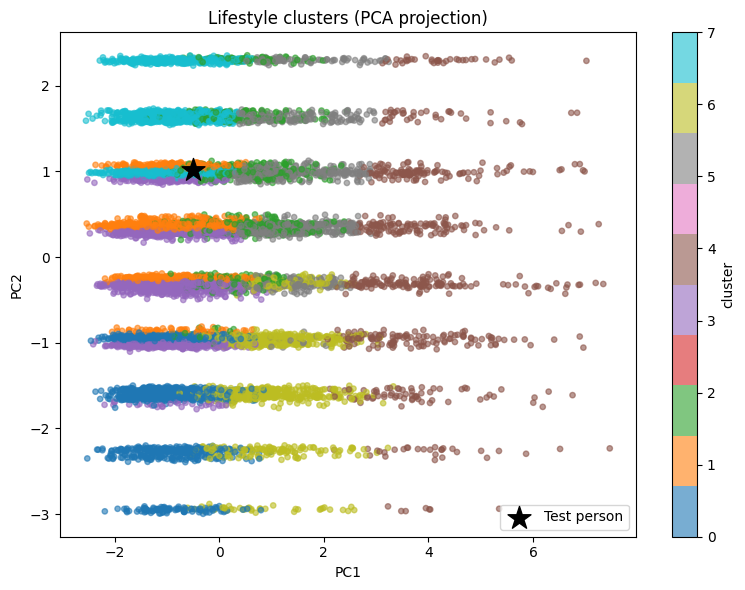

In [16]:

pca = PCA(n_components=2, random_state=RANDOM_SEED)
coords = pca.fit_transform(feature_df.values)
test_coords = pca.transform(test_vec.values.reshape(1, -1))

plt.figure(figsize=(8, 6))
scatter = plt.scatter(coords[:, 0], coords[:, 1], c=df_indexed["lifestyle_cluster"], cmap="tab10", alpha=0.6, s=15)
plt.scatter(test_coords[:, 0], test_coords[:, 1], c="black", marker="*", s=300, label="Test person")
plt.legend()
plt.title("Lifestyle clusters (PCA projection)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.colorbar(scatter, label="cluster")
plt.tight_layout()
plt.show()



## 12. How to extend this

- **Switch algorithms**: change `ACTIVE_ALGORITHM` in Section 7 (or pass `method=` to any call) to one of `"rule_based"`, `"clustering"`, `"nearest_neighbor"`, `"ml_model"`.
- **Add a new algorithm**: write a function `my_algo(id_a, id_b, feature_df=...) -> float` and add an `elif` branch to `get_compatibility`.
- **Change the fit-rule**: edit the weights inside `rule_based_compatibility` (Section 5) — the ML model will automatically learn the new rule the next time it's retrained on refreshed labels.
- **Real deployment**: replace the `df.sample(...)` seeding in Section 8 with your actual room/tenant records, and persist `feature_df_ext` incrementally instead of rebuilding it from scratch each time.
